# Excercise 1: Introduction to PyTorch

In this excercise, you will learn how to use the basic concepts of PyTorch to build a simple classifier, which can detect different types of animals and vehicles. We recommend running this notebook on a machine with a GPU, here are two ways you could achieve this:

### HU Jupyterhub (Recommended)

The HU offers [Jupyterhub](https://www.digitale-lehre.hu-berlin.de/de/lehr-und-lernlandschaft/jupyterhub), a service to run Jupyter Notebooks. You should chose a runtime that offers GPU support (for example the CUDA runtime). The notebooks run in your browser and the code is executed on HU servers.

### Google Colab

The [Colab](https://colab.research.google.com/) service is another way to run jupyter notebooks in your browser, using machines provided by google to run the code. It is free to the extend we are going to make use of it in this lecture, however you need a google account to run it, and GPUs might not be available.

To get GPU support, open this file in colab, go to `Edit -> Notebook Settings` on the top left and select any of the available GPUs.

### Run the code locally (not Recommended)

If you want to dive deeper, you can run this notebook locally on your machine. For that, you will need to set up an environment with `numpy`, `torch`, `matplotlib`, `sklearn` and `PIL` installed. If you want to run the code on your graphics card, you will also have to install CUDA to your machine. This can get a bit hacky, so be warned.   

## 1.1 Confirm the environmet set up

Here, you don't have to do anything yet, just run the code and see if you set up the environment correctly.

In [2]:
import time, os, math, random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import CIFAR10
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import itertools
from PIL import Image
from typing import List

try:
    from google.colab import files

    IN_COLAB = True
except Exception:
    IN_COLAB = False

has_gpu = torch.accelerator.is_available()
device = torch.accelerator.current_accelerator().type if has_gpu else "cpu"

class DL4CV_CIFAR10(CIFAR10):
    url = "https://datacloud.hhi.fraunhofer.de/s/X5xQrWLF6i4GmnS/download"

print(f"You are working {'' if IN_COLAB else 'not'} in colab, and the GPU is {'' if has_gpu else 'not '}enabled.")


You are working not in colab, and the GPU is enabled.


## 1.2 Dataset

The classifier will be trained on the [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html). It was published by the university of Toronto in 2009 and consists of 60000 32x32 colour images in 10 classes, with 6000 images per class. There are 50000 training images and 10000 test images. It is already implemented as a PyTorch dataset, so we can download it using the following lines of code.

In [3]:
CLASSES = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
]
train_set = DL4CV_CIFAR10(
    root="./data", train=True, download=True
)
test_set = DL4CV_CIFAR10(
    root="./data", train=False, download=True
)

Take a second to get familiar with the dataset.
- Finish the implementation of the `display_entry`, where we display the PIL image and the name of the associated class.
- Finish the implementation of the `early_bird` function, it should display the first occurence of a bird in the `train_dataset`.

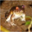

The image shows a frog.



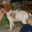

The image shows a dog.



In [4]:


def display_entry(dataset, index: int):
  image = dataset[index][0]
  label = CLASSES[dataset[index][1]]

  display(image)
  print(f"The image shows a {label}.")
  print("")

def early_bird():
  bird_index = CLASSES.index("bird")
  for image, label in train_set:
    if label == bird_index:
      display(image)
      print("This Image shows the a ", CLASSES[bird_index])
    break

display_entry(train_set, 0)
display_entry(test_set, 12)
early_bird()



## 1.3 Data Transformation

The images in the Datasets are in RGB format with integer values from $0$ to $255$. This is not optimal for machine learning algorithms. Different models and datasets call for different input transformations. For the CIFAR-10 set, the [community decided](https://github.com/facebookarchive/fb.resnet.torch/issues/180) it is best to normalize the data around their mean and standard deviation. Familiarize yourself with the [`torchvision.transforms`](https://docs.pytorch.org/vision/stable/transforms.html#v1-api-reference) API. The input transformation for the test dataset is already given to you.

To get more versatile training data, we want to use augmentation transforms before converting the image to a tensor. Therefore, we want to pad the images by $4$px and randomly crop a $32\times32$ subsample from the padded image. After that, we want randomly want to mirror the image horizontally.


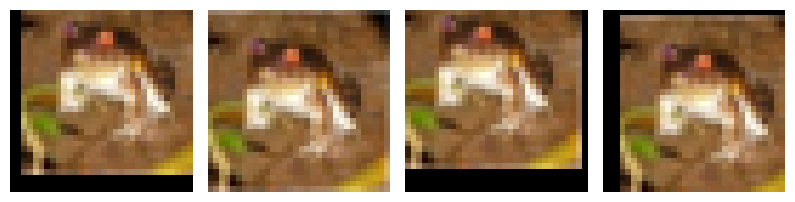

In [5]:
MEAN = [0.4914, 0.4822, 0.4465]
STD = [0.2470, 0.2435, 0.2616]

def tensor_to_np_image(img: torch.Tensor):
  mean = torch.tensor(MEAN).view(3, 1, 1)
  std = torch.tensor(STD).view(3, 1, 1)
  img = img.cpu() * std + mean
  img = img.clamp(0, 1)
  return np.transpose(img.numpy(), (1, 2, 0))

def display_grid(images:List[np.ndarray]):
  plt.figure(figsize=(12, 2.5*len(images)))
  for i, img in enumerate(images):
      plt.subplot(4, 6, i + 1)
      img_np = tensor_to_np_image(img)
      plt.imshow(img_np)
      plt.axis("off")
  plt.tight_layout()
  plt.show()


test_transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ]
)

train_transform = transforms.Compose(
    [
        transforms.Pad(4), # padding of 4px
        transforms.RandomCrop(32),  # random crop of 32x32
        transforms.RandomHorizontalFlip(0.5), #50% chance of image getting flipped
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ]
)

train_set.transform = train_transform
test_set.transform = test_transform


# plot the transformed images, you should see different augmentations of a frog
images = [train_set[0][0] for _ in range(4)]
display_grid(images)

## 1.4 Tensors

Tensors are the most important underlying data structure in PyTorch. Therefore, try to take a moment and understand them a bit more.

Implement the `print_info` function, that prints the shape of the image, the mean value, the device it is stored on and the first 8 values of the first row of the tensor to the output. Furthermore, implement the `move_to_gpu` function, that moves the tensor to the GPU device.
Answer the questions in the free text field underneath the code box

In [6]:
image_tensor = test_set[0][0]

def print_info(img:torch.Tensor):
  image_shape = img.shape
  image_mean = torch.mean(img)
  first_pixels = img.view(-1)[:8]
  image_device = img.device

  print(f"The image has shape f{image_shape} and is stored on the {image_device} device.")
  print(f"The average value of the image tensor is {image_mean}, and the first 8 values look the following:")
  print(first_pixels)

def move_to_gpu(img:torch.Tensor):
  return img.to('cuda:0')



print_info(image_tensor)
print("")
gpu_tensor = move_to_gpu(image_tensor)
print_info(gpu_tensor)


The image has shape ftorch.Size([3, 32, 32]) and is stored on the cpu device.
The average value of the image tensor is -0.19376488029956818, and the first 8 values look the following:
tensor([0.5191, 0.5349, 0.6302, 0.6461, 0.5508, 0.4873, 0.5826, 0.5349])

The image has shape ftorch.Size([3, 32, 32]) and is stored on the cuda:0 device.
The average value of the image tensor is -0.19376489520072937, and the first 8 values look the following:
tensor([0.5191, 0.5349, 0.6302, 0.6461, 0.5508, 0.4873, 0.5826, 0.5349],
       device='cuda:0')


### Why is the image in that shape? What do the individual channels represent?

The image has the shape of 3, 32, 32 as it has the size of 32x32 pixels. For each pixel we have 3 Color Values (Red, Green, Blue)

### What can you say about the image from looking at the mean of the tensor? How did we achieve that mean?

TODO

### for integers `x,y,z`, what does `image_tensors[x,y,z]` represent? What values can be used for `x,y,z`, and what changes in an image if `image_tensors[x,y,z]` gets set to a higher or lower value?

TODO

Implement some image augmentation methods that work on the tensor of an image. The `saturate` method takes an image and intensifies all  color values for all pixels of an image by $100\%$. The `switch_red_and_blue` method switches the red and blue channel of an image.

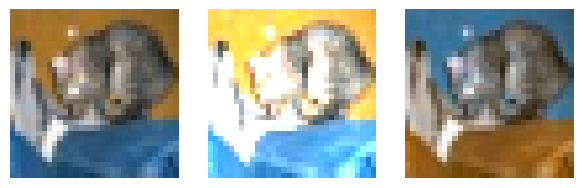

In [7]:
def saturate(img:torch.Tensor):
  mean = torch.tensor(MEAN).view(3, 1, 1)
  std = torch.tensor(STD).view(3, 1, 1)
  img = img.cpu() * std + mean
  img = (img *2).clamp(0, 1)
  out_img = (img - mean) / std
  return out_img

def switch_red_and_blue(img:torch.Tensor):
  out_img = img.clone()
  out_img[[0,2]] = out_img[[2,0]]
  return out_img

results = [image_tensor, saturate(image_tensor), switch_red_and_blue(image_tensor)]
display_grid(results)

## 1.5 Model

Now, we build the model to classify the images. We will build a CNN consisting of three blocks that change the images size from an original $32\times32$ to a $4\times4$ block. After that, an MLP is using this, to output a $1\times10$ thensor, representing the confidence value for each class.

Finish the implementation of the `self.features` attribute, the first block is already given to you, you can follow this architecture for the other two blocks. Furthermore, plug together the `self.features` and `self.classifier` in the `forward` pass of the model.

In [8]:
class CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: 3x32x32 -> 32x16x16
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Block 2: 32x16x16 -> 64x8x8
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64,64,kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Block 3: 64x8x8 -> 128x4x4
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128,128,kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, image:torch.Tensor):
        features = self.features(image)
        classified = self.classifier(features)
        return classified

# Verify that your model works, the output shape should be 1x10

model = CNN()
image = test_set[0][0].unsqueeze(dim = 0)
print(model(image).shape)


torch.Size([1, 10])


### Why is there no activation funciton after the last classifier linear layer?


TODO


## Training

We are going to make use of the PyTorch autograd and optimizer features to implement the training loop.

As the model outputs confidence scores, your first task is to implement the `get_prediction()` method, that returns the index of the class with the highest confidence.

The `evaluate()` method will be called on the test dataset, to get accuracy and loss for the test data, it is already implemented for you. You have to implement the `train_one_epoch()` method, which will be called on the train dataset. It behaves similarly to the `evaluate()` method, but you have to take care of calling doing the backward pass and the optimizer step. Make sure, to call the `zero_grad()` function before calculating the gradients.

As a loss function, as this is a classification problem, a good choice is the [Cross Entropy Loss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html), for the optimizer, use the [Adam Optimizer](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html).

If you have access to a GPU accelerator, the whole model training should not take longer than 5 minutes, on a CPU it could take about 45 minutes. If you don't want to wait so long, you could decrease the number of `EPOCHS` for training.

In [9]:
BATCH_SIZE = 128
train_loader = DataLoader(
    train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=2
)
test_loader = DataLoader(
    test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2
)

In [ ]:
model = CNN().to('cuda:0')

def get_prediction(confidences:torch.Tensor):
  preds = confidences
  preds = torch.argmax(preds, dim=1)
  return preds

@torch.no_grad()
def evaluate(model, loader, loss_fn, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        logits = model(x)
        loss = loss_fn(logits, y)

        running_loss += loss.item() * x.size(0)
        preds = get_prediction(confidences=logits)
        correct += (preds == y).sum().item()
        total += x.size(0)

    avg_loss = running_loss / total
    acc = correct / total
    return avg_loss, acc


def train_one_epoch(model, loader, loss_fn, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad()
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * x.size(0)
        preds = get_prediction(confidences=logits)
        correct += (preds == y).sum().item()
        total += x.size(0)

    avg_loss = running_loss / total
    acc = correct / total
    return avg_loss, acc




loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters())
EPOCHS = 8
train_losses, test_losses = [], []
train_accs, test_accs = [], []

start = time.time()
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    _,_ = train_one_epoch(model, train_loader, loss_fn, optimizer, device)
    te_loss, te_acc = evaluate(model, test_loader, loss_fn, device)
    tr_loss, tr_acc = evaluate(model, train_loader, loss_fn, device)
    train_losses.append(tr_loss)
    test_losses.append(te_loss)
    train_accs.append(tr_acc)
    test_accs.append(te_acc)
    print(
        f"Epoch {epoch:01d}/{EPOCHS} | "
        f"train loss {tr_loss:.4f}, acc {tr_acc*100:.1f}% | "
        f"test loss {te_loss:.4f}, acc {te_acc*100:.1f}% | "
        f"time {time.time()-t0:.1f}s"
    )
print(f"Total training time: {time.time()-start:.1f}s")




## Evaluation

Finally, see if your model is actually doing what it is supposed to do. As a first task, use matplotlib to plot the accuracies and losses over time. The loss already implemented, you just have to add the code for the accuracy curves.

In [ ]:
epochs = np.arange(1, EPOCHS + 1)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, test_losses, label="Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.grid(True)
plt.legend()

#TODO



Evaluate your results qualitatively. A function for evaluation is already given. Just answer the questions in the free text field below.

In [ ]:
# @title
@torch.no_grad()
def sample_batch_and_show(model, loader, classes, n_show=12):
    model.eval()
    x, y = next(iter(loader))
    x, y = x.to(device), y.to(device)
    logits = model(x)
    preds = get_prediction(logits)
    rows = int(math.ceil(n_show / 6))
    plt.figure(figsize=(12, 2.5 * rows))
    for i in range(n_show):
        plt.subplot(rows, 6, i + 1)
        img = tensor_to_np_image(x[i])
        plt.imshow(img)
        p, t = classes[preds[i].item()], classes[y[i].item()]
        color = "green" if preds[i].item() == y[i].item() else "red"
        plt.title(f"P: {p}\nT: {t}", color=color, fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


sample_batch_and_show(model, test_loader, CLASSES, n_show=12)




### How well would you say does your model perform qualitatively?

TODO

### Where does you model not perform well?

TODO

### What could be done to mitigate these issues?

TODO

Can your model bridge the gap to real world data? Beneath, we provided some code that let's you upload an image to colab. Take an image of your pet, a car on the street or anything that your model should be able to classify and run an inference on that image to see if it works. If you don't use colab, change the line of code that specifies a path to a local image or an image uploaded to the HU Jupyterhub. Answer the questions beneath.

Keep in mind, the model was trained on square images, you should crop your image to a square before uploading.

In [ ]:
# @title
def predict_image(model, img_path, device):
    img = Image.open(img_path).convert("RGB")
    transform = transforms.Compose(
        [
            transforms.Resize((32, 32)),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ]
    )
    x = transform(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1)[0]
        topk = torch.topk(probs, k=3)
    top_classes = [CLASSES[i] for i in topk.indices.cpu().numpy()]
    top_probs = topk.values.cpu().numpy()
    return top_classes, top_probs, img


def show_uploaded_prediction(model):
    if IN_COLAB:
        print("Upload an image (jpg/png)...")
        uploaded = files.upload()
        if not uploaded:
            print("No file uploaded.")
            return
        path = list(uploaded.keys())[0]
    else:
        path = "fjorencio_the_dog.jpeg" #TODO: if you're not using colab, just hard code a path in your system here

    top_classes, top_probs, img = predict_image(model, path, device)
    plt.figure(figsize=(3, 3))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Uploaded image")
    plt.show()
    print("Top-3 predictions:")
    for c, p in zip(top_classes, top_probs):
        print(f"{c}: {p:.3f}")

show_uploaded_prediction(model)


### Could you find a difference in performance on real world data?

TODO
